# Lesson 23 - Adding feature sets one at a time, what they cost, and fewer mel bands

Still 6 classes + other (lesson 22), same folds, weights and protocol.

**Question 3: which feature sets are worth their cost?** Lesson 15 left groups out and added them, but never
measured what a feature costs to compute. Here every feature set gets a price, in milliseconds per 5-s clip on one
CPU thread, and the sets are added **one at a time**:

1. each of the nine sets is scored alone (validation folds of all five rounds) and they are put in order, best first;
2. start with the best set; add the next one: **if the validation score goes up, keep it; if not, leave it out**
   and try the following set on top of the last kept one;
3. every step records the numbers per clip and the milliseconds per clip, so the gain can be weighed against the
   cost; the final set is then tested once, like every other set.

Each step is judged by a logistic regression with a fixed C (fast: 1-20 s per fold). The final set is tested with
both models.

**Questions 4 and 5: fewer mel bands.** The cached spectrogram has 128 mel bands (10 Hz-16 kHz). Two ways to use
fewer: merge neighbouring bands (64, 32, 16 bands over the same range), or keep only the lowest 20, 30, 40 or 64
bands (everything above their top frequency is dropped). Each as band mean + spread, both models, 5 folds.

```
python src/with_other.py cost bands       # -> runs/with_other/costs.json, walk.jsonl, cost.jsonl, bands.jsonl
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import with_other as W

OUT = W.OUT_DIR
costs = json.loads((OUT / "costs.json").read_text())
walk = pd.DataFrame(W.Log(OUT / "walk.jsonl").rows)
result = json.loads((OUT / "walk_result.json").read_text())
tested = pd.DataFrame(W.Log(OUT / "cost.jsonl").rows)
main = pd.DataFrame(W.Log(OUT / "main.jsonl").rows)
bands = pd.DataFrame(W.Log(OUT / "bands.jsonl").rows)
pd.set_option("display.width", 170)
MODEL_COLORS = {"gradient boosting": "#2a78d6", "logistic regression": "#eb6834"}


def pm(g, col):
    return (100 * g[col].mean()).round(1).astype(str) + " ± " + (100 * g[col].std()).round(1).astype(str)

## 1. What each feature set costs

Measured on 120 clips, one CPU thread, median per clip. Some work is shared: the 128-band mel spectrogram (both mel
sets), a short-window STFT (MFCC, level changes, spectral shape) and the long-term Welch spectrum (1/3-octave
levels, loudness, tonal lines). A shared step is paid once, whichever of its sets are used. Reading and decoding the
clip is paid by every set.

reading and decoding one clip: 15.9 ms
                              numbers  own (ms)                  shared step  shared step (ms)  alone, with reading (ms)
set                                                                                                                     
mel mean + spread                 257       0.2  mel spectrogram (128 bands)              29.0                      45.0
mel percentiles                   384       1.2  mel spectrogram (128 bands)              29.0                      46.0
MFCC                               57       1.5          STFT (2,048 window)               7.4                      24.8
level changes over time             9       0.9          STFT (2,048 window)               7.4                      24.2
spectral shape                     28      12.4          STFT (2,048 window)               7.4                      35.7
1/3-octave levels                  29       0.6               Welch spectrum               7.7                    

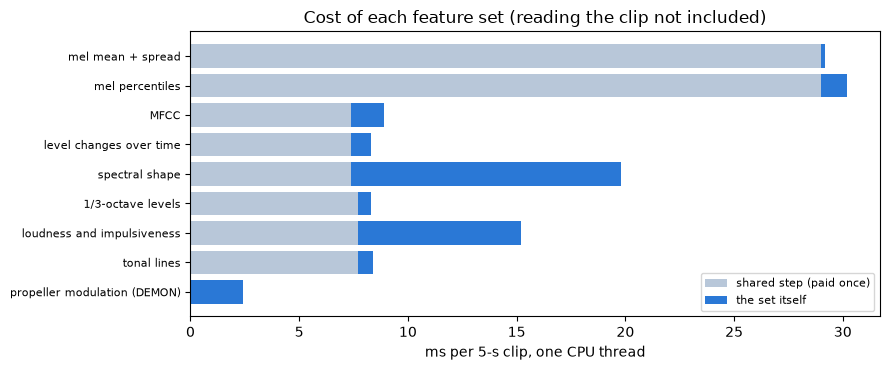

In [2]:
sets9 = list(W.PREREQ)
rows = []
for g in sets9:
    pre = W.PREREQ[g]
    rows.append({"set": g, "numbers": int(walk[(walk.stage == "alone") & (walk.groups == g)].n_features.iloc[0]),
                 "own (ms)": round(costs[g], 1), "shared step": pre or "-",
                 "shared step (ms)": round(costs[pre], 1) if pre else 0.0,
                 "alone, with reading (ms)": round(W.subset_cost([g], costs), 1)})
cost_table = pd.DataFrame(rows).set_index("set")
print(f"reading and decoding one clip: {costs['read and decode']:.1f} ms")
print(cost_table.to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(cost_table))
ax.barh(y, cost_table["shared step (ms)"], color="#b8c7d9", label="shared step (paid once)")
ax.barh(y, cost_table["own (ms)"], left=cost_table["shared step (ms)"], color="#2a78d6", label="the set itself")
ax.set_yticks(y, cost_table.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("ms per 5-s clip, one CPU thread")
ax.legend(fontsize=8); ax.set_title("Cost of each feature set (reading the clip not included)"); plt.tight_layout(); plt.show()

- **Every set pays 16 ms to read and decode the clip; both mel sets pay 29 ms for the 128-band mel spectrogram.**
  Once the spectrogram exists, its mean, spread (0.2 ms) and percentiles (1.2 ms) are almost free.
- **The engineered groups share two cheaper spectra** (a short-window STFT, 7 ms; the long-term Welch spectrum, 8 ms);
  on top, most groups cost 1-2 ms. Two are expensive: **spectral shape (12 ms)**, seven statistics over 309 frames
  of 1,025 bins, and **loudness and impulsiveness (7.5 ms)**, which recomputes the 1/3-octave levels and takes the
  kurtosis and crest factor of all 160,000 samples.
- All 144 engineered numbers: 57 ms per clip; with the mel mean + spread as well (lesson 22's best set): 86 ms.
  One CPU core handles a 5-s clip about 60 times faster than real time either way, so cost decides between sets of
  equal accuracy, not whether a set is usable.

## 2. Adding the sets one at a time

In [3]:
alone = walk[walk.stage == "alone"].set_index("groups").loc[result["order"]]
print("each set alone (validation, mean of 5 rounds), the order of the walk:")
print(pd.DataFrame({"validation (%)": (100 * alone.val).round(1), "numbers": alone.n_features,
                    "ms per clip": alone.ms.round(1)}).to_string())

steps = walk[walk.stage == "walk"].sort_values("step")
first = result["order"][0]
rows = [{"step": 1, "added": first, "validation (%)": round(100 * result["alone"][first], 2), "change (points)": "",
         "kept": "start", "numbers": int(alone.n_features.iloc[0]), "ms per clip": round(alone.ms.iloc[0], 1)}]
for s in steps.itertuples():
    rows.append({"step": s.step, "added": s.added, "validation (%)": round(100 * s.val, 2),
                 "change (points)": f"{100 * (s.val - s.before):+.2f}", "kept": "yes" if s.val > s.before else "no",
                 "numbers": s.n_features, "ms per clip": round(s.ms, 1)})
walk_table = pd.DataFrame(rows).set_index("step")
print("\nthe walk (numbers and ms are those of the set tried at that step):")
print(walk_table.to_string())
print(f"\nfinal set: {result['final']}")

each set alone (validation, mean of 5 rounds), the order of the walk:
                              validation (%)  numbers  ms per clip
groups                                                            
mel percentiles                         47.6      384         46.0
mel mean + spread                       46.6      257         45.0
1/3-octave levels                       45.5       29         24.2
spectral shape                          43.3       28         35.7
loudness and impulsiveness              41.3        5         31.0
MFCC                                    39.7       57         24.8
propeller modulation (DEMON)            31.4       11         18.3
tonal lines                             28.6        5         24.2
level changes over time                 26.0        9         24.2

the walk (numbers and ms are those of the set tried at that step):
                             added  validation (%) change (points)   kept  numbers  ms per clip
step                         

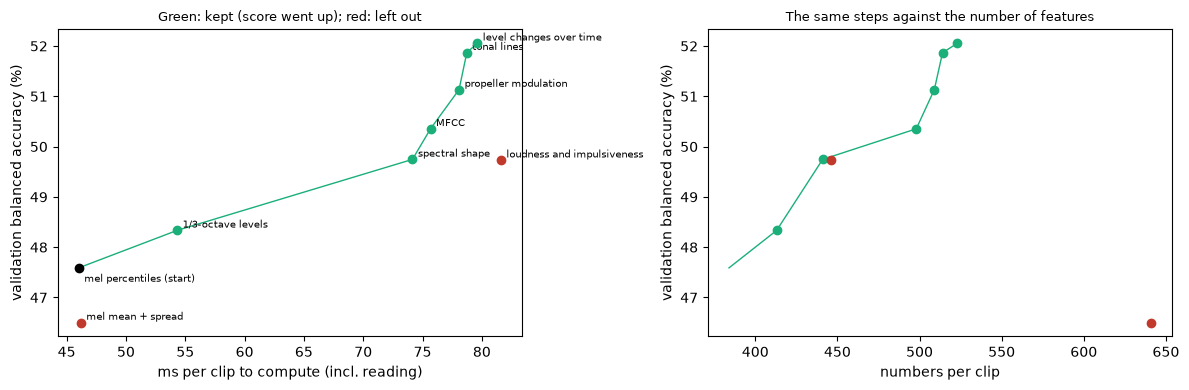

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
kept_val, kept_ms, kept_n = [100 * result["alone"][first]], [alone.ms.iloc[0]], [alone.n_features.iloc[0]]
for s in steps.itertuples():
    color = "#1baf7a" if s.val > s.before else "#c0392b"
    ax[0].scatter(s.ms, 100 * s.val, color=color, zorder=3)
    ax[0].annotate(s.added.split(" (")[0], (s.ms, 100 * s.val), fontsize=7, xytext=(4, 2), textcoords="offset points")
    ax[1].scatter(s.n_features, 100 * s.val, color=color, zorder=3)
    if s.val > s.before:
        kept_val.append(100 * s.val); kept_ms.append(s.ms); kept_n.append(s.n_features)
ax[0].plot(kept_ms, kept_val, color="#1baf7a", lw=1); ax[1].plot(kept_n, kept_val, color="#1baf7a", lw=1)
ax[0].scatter(alone.ms.iloc[0], 100 * result["alone"][first], color="black", zorder=3)
ax[0].annotate(first + " (start)", (alone.ms.iloc[0], 100 * result["alone"][first]), fontsize=7, xytext=(4, -10),
               textcoords="offset points")
ax[0].set_xlabel("ms per clip to compute (incl. reading)"); ax[1].set_xlabel("numbers per clip")
for a in ax:
    a.set_ylabel("validation balanced accuracy (%)")
ax[0].set_title("Green: kept (score went up); red: left out", fontsize=9)
ax[1].set_title("The same steps against the number of features", fontsize=9)
plt.tight_layout(); plt.show()

- **Alone, the mel statistics come first** (percentiles 47.6 %, mean + spread 46.6 %), then the 1/3-octave levels
  (45.5 %, only 29 numbers); level changes (26.0 %) and tonal lines (28.6 %) are weak alone.
- **Seven of the nine sets are kept.** Each kept step adds 0.2-1.4 points; the largest are spectral shape (+1.4),
  DEMON (+0.8), 1/3-octave levels (+0.7), tonal lines (+0.7) and MFCC (+0.6).
- **Two are left out:** mel mean + spread (-1.1 points; the percentiles of the same bands already carry the level)
  and loudness and impulsiveness (-0.02 points, and the second most expensive engineered group, 7.5 ms). Lesson 15
  had also found that loudness and impulsiveness can go.
- **Weak alone is not useless:** tonal lines and level changes are among the weakest sets on their own, but they
  still add to the others, because they measure something the others don't (engine lines, how steady the sound is).
- **The walk is cheap and simple:** 17 steps, each a logistic regression on five validation folds. Its order comes
  from each set's score alone, and every set is judged once: a set left out early is not tried again later.

## 3. The final set on the test folds

In [5]:
g = tested.groupby(["features", "model"], sort=False)
t = pd.DataFrame({"numbers": g.n_features.first(), "ms per clip": g.ms.first().round(1),
                  "per clip": pm(g, "balanced_accuracy"), "per ship": pm(g, "per_ship_balanced_accuracy"),
                  "final fit (s)": g.seconds_fit.mean().round(0), "predict (µs/clip)": g.predict_us_per_clip.mean().round(1)})
main_ms = {"mel mean + spread (257)": ["mel mean + spread"],
           "mel mean + spread + percentiles (641)": ["mel mean + spread", "mel percentiles"],
           "engineered (144)": sets9[2:], "engineered + mel mean + spread (401)": sets9[2:] + ["mel mean + spread"],
           "engineered + mel mean + spread + percentiles (785)": sets9}
gm = main.groupby(["features", "model"], sort=False)
tm = pd.DataFrame({"numbers": gm.n_features.first(), "per clip": pm(gm, "balanced_accuracy"), "per ship": pm(gm, "per_ship_balanced_accuracy"),
                   "final fit (s)": gm.seconds_fit.mean().round(0), "predict (µs/clip)": gm.predict_us_per_clip.mean().round(1)})
tm.insert(1, "ms per clip", [round(W.subset_cost(main_ms[f], costs), 1) for f, _ in tm.index])
print("walk results (test, 5 folds):")
print(t.to_string())
print("\nlesson 22's sets, for comparison:")
print(tm.to_string())

walk results (test, 5 folds):
                                                                                                                                                        numbers  ms per clip    per clip    per ship  final fit (s)  predict (µs/clip)
features                                                                                                                           model                                                                                              
mel percentiles                                                                                                                    logistic regression      384         46.0  48.4 ± 1.6  55.1 ± 2.1           14.0                3.5
                                                                                                                                   gradient boosting        384         46.0  48.2 ± 1.3  54.0 ± 2.7          158.0               44.2
mel percentiles | 1/3-octave levels | spectral

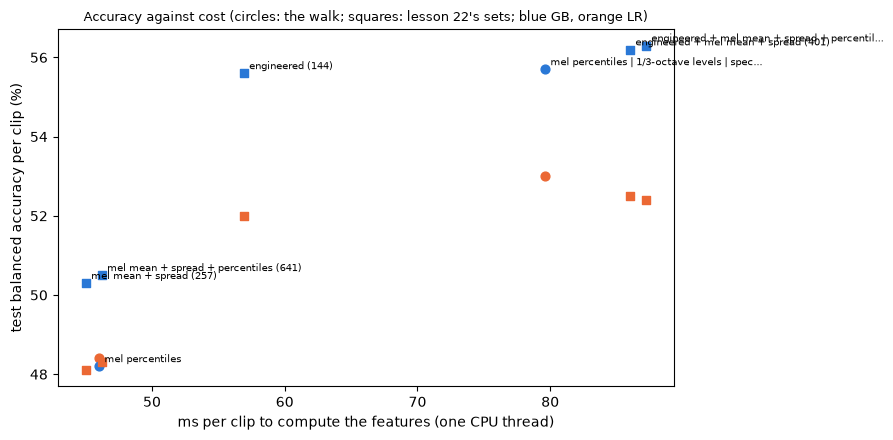

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for frame, marker in ((t, "o"), (tm, "s")):
    for (feat, model), row in frame.iterrows():
        acc = float(row["per clip"].split(" ± ")[0])
        ax.scatter(row["ms per clip"], acc, color=MODEL_COLORS[model], marker=marker, s=40)
        if model == "gradient boosting":
            ax.annotate(feat if len(feat) < 45 else feat[:42] + "...", (row["ms per clip"], acc), fontsize=7,
                        xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("ms per clip to compute the features (one CPU thread)"); ax.set_ylabel("test balanced accuracy per clip (%)")
ax.set_title("Accuracy against cost (circles: the walk; squares: lesson 22's sets; blue GB, orange LR)", fontsize=9)
plt.tight_layout(); plt.show()

- **The walk's set on the test folds:** gradient boosting 55.7 ± 0.6 % per clip, 63.6 ± 2.6 % per ship; logistic
  regression 53.0 / 59.8 %. That is level with lesson 22's best set (engineered + mel mean + spread: 56.2 / 65.0 %,
  86 ms per clip) at about the same cost (80 ms).
- **Judged with logistic regression, used with gradient boosting:** the walk dropped mel mean + spread because it
  lowered the logistic regression's score; for gradient boosting the same numbers still help a little (lesson 22).
  A walk judged with gradient boosting would take about 2 hours (85 fits of 1-2 minutes) instead of half an hour.
- **Accuracy against cost:** the mel percentiles alone cost 46 ms per clip; the six sets added after them bring +4.5
  points of validation accuracy for 34 ms more. The largest single gain, spectral shape (+1.4), is also the most
  expensive group (12 ms). The 785-number set costs about as much to compute as the 401-number set, but almost four
  times as long to train, for no gain.

## 4. Fewer mel bands: merged, or only the lowest ones

In [7]:
g = bands.groupby(["features", "model"], sort=False)
bt = pd.DataFrame({"numbers": g.n_features.first(), "per clip": pm(g, "balanced_accuracy"),
                   "per ship": pm(g, "per_ship_balanced_accuracy")})
ref = bands[bands.features.str.startswith("128 bands")].groupby("model").balanced_accuracy.mean()
bt["vs 128 bands (points)"] = [f"{100 * (bands[(bands.features == f) & (bands.model == m)].balanced_accuracy.mean() - ref[m]):+.1f}"
                               for f, m in bt.index]
print("band mean + spread only, 6 classes + other, test (mean ± spread of 5 folds):")
print(bt.to_string())

band mean + spread only, 6 classes + other, test (mean ± spread of 5 folds):
                                                                     numbers    per clip    per ship vs 128 bands (points)
features                                        model                                                                     
128 bands, 10 Hz-16 kHz                         logistic regression      256  48.1 ± 1.4  55.3 ± 1.9                  +0.0
                                                gradient boosting        256  50.4 ± 1.3  57.7 ± 2.7                  +0.0
64 bands (neighbours merged by 2), 10 Hz-16 kHz logistic regression      128  47.9 ± 1.4  54.4 ± 1.8                  -0.2
                                                gradient boosting        128  49.5 ± 1.0  56.3 ± 1.4                  -0.9
32 bands (neighbours merged by 4), 10 Hz-16 kHz logistic regression       64  46.7 ± 1.6  53.1 ± 1.4                  -1.4
                                                gradient boost

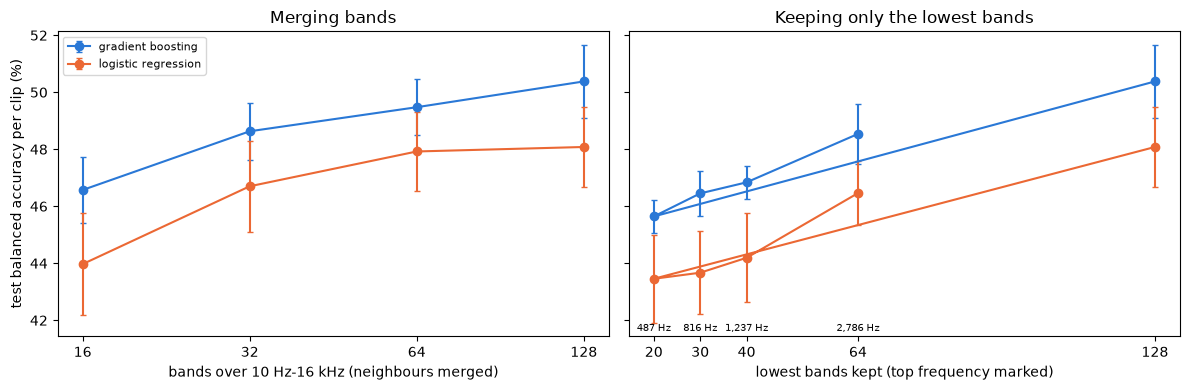

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for model, color in MODEL_COLORS.items():
    b = bands[bands.model == model]
    merged = b[~b.features.str.startswith("lowest")].groupby("features", sort=False).balanced_accuracy
    nb = [int(f.split(" ")[0]) for f in merged.mean().index]
    ax[0].errorbar(nb, 100 * merged.mean().values, yerr=100 * merged.std().values, marker="o", capsize=2, color=color, label=model)
    low = b[b.features.str.startswith("lowest") | b.features.str.startswith("128 bands")].groupby("features", sort=False).balanced_accuracy
    nl = [128 if f.startswith("128") else int(f.split(" ")[1]) for f in low.mean().index]
    ax[1].errorbar(nl, 100 * low.mean().values, yerr=100 * low.std().values, marker="o", capsize=2, color=color, label=model)
for n in W.LOWEST:
    ax[1].annotate(f"{W.top_hz_of_lowest(n):,.0f} Hz", (n, ax[1].get_ylim()[0]), fontsize=7, ha="center", xytext=(0, 4), textcoords="offset points")
ax[0].set_xscale("log", base=2); ax[0].set_xticks([16, 32, 64, 128], ["16", "32", "64", "128"])
ax[0].set_xlabel("bands over 10 Hz-16 kHz (neighbours merged)"); ax[0].set_ylabel("test balanced accuracy per clip (%)")
ax[1].set_xticks([20, 30, 40, 64, 128]); ax[1].set_xlabel("lowest bands kept (top frequency marked)")
ax[0].set_title("Merging bands"); ax[1].set_title("Keeping only the lowest bands")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

- **No reduction helps; every one costs, and the cost grows with the cut.** Gradient boosting, per clip, against all
  128 bands (50.4 %): 64 merged bands -0.9, 32 -1.8, 16 -3.8 points; only the lowest 64 bands (up to 2.8 kHz) -1.9,
  40 bands (1.2 kHz) -3.6, 30 bands (816 Hz) -3.9, 20 bands (487 Hz) -4.8. Logistic regression moves the same way.
- **Merging is cheaper than cutting:** 64 merged bands (128 numbers) lose 0.9 points; the lowest 64 bands (also 128
  numbers) lose 1.9. Keeping the whole range at a coarser resolution beats a fine resolution of the low end only,
  as in lesson 15 without "other".
- **The lowest 20 bands already carry most of it:** 40 numbers below 487 Hz give 45.6 %, 90 % of the full 50.4 %.
  The remaining 108 bands, up to 16 kHz, add the last 4.8 points.
- **Why not fewer bands, then?** The model would get smaller (128 instead of 256 numbers for 64 bands), but the
  computing cost hardly changes: the 128-band spectrogram (29 ms) has to be made first either way, and merging or
  cutting it is almost free. So fewer bands save training time and memory, not the per-clip cost, and they always
  cost accuracy.

## 5. What it means

| Question | Answer (6 classes + other, 5 test folds) |
|---|---|
| 3. Which feature sets are worth their cost? | Added one at a time: 7 of 9 kept (523 numbers, 80 ms per clip), 55.7 % per clip; level with lesson 22's best set (56.2 %, 86 ms). Loudness and impulsiveness is dropped again. |
| 4. Fewer mel bands (64 / 32 / 16)? | -0.9 / -1.8 / -3.8 points (gradient boosting); no gain, and no saving in computing time per clip. |
| 5. Only the lowest 20 / 30 / 40 bands? | -4.8 / -3.9 / -3.6 points; the high frequencies still matter with "other". |

Keep all 128 bands, and the engineered features with the mel mean + spread (lesson 22). Most of the per-clip cost
is reading the clip and making one spectrogram; the choice between equally good sets is a matter of training time.